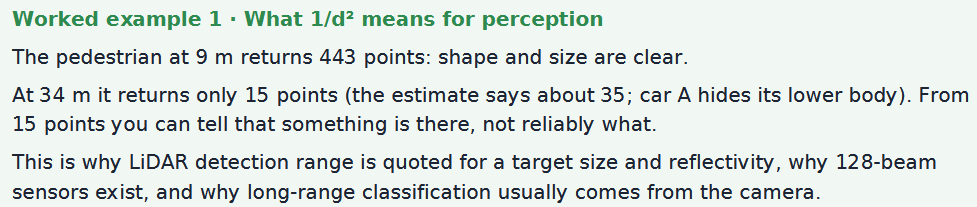

In [1]:
import sys; sys.path.insert(0, "..")          # the notebook runs inside notebooks/
import numpy as np
from src import scene
from src.pointcloud import points_on_target

rng = np.random.default_rng(0)
points, labels, cloud = scene.simulate_scan(rng)

# 1. rule of thumb vs. simulated scan
print("distance   estimate   simulated")
for lab, dist in [(20, 9), (21, 34)]:
    rows, cols, n = points_on_target(height=1.75, width=0.6, distance=dist)
    print(f"{dist:5d} m   {n:7.0f}    {np.sum(labels == lab):8d}   "
          f"({rows:.1f} beams x {cols:.1f} columns)")

# 2. how much does car A hide? run the same scan without car A
boxes_saved = list(scene.BOXES)
scene.BOXES[:] = [b for b in scene.BOXES if b[0] != 10]      # remove car A (label 10)
_, labels_free, _ = scene.simulate_scan(np.random.default_rng(0))
scene.BOXES[:] = boxes_saved                                  # put it back
print(f"\npedestrian at 34 m without car A in front: {np.sum(labels_free == 21)} points")

# 3. the 1/d^2 law
for d in [10, 20, 40, 80]:
    print(f"pedestrian at {d:2d} m: ~{points_on_target(1.75, 0.6, d)[2]:5.0f} points")

distance   estimate   simulated
    9 m       495         443   (25.9 beams x 19.1 columns)
   34 m        35          15   (6.9 beams x 5.1 columns)

pedestrian at 34 m without car A in front: 34 points
pedestrian at 10 m: ~  401 points
pedestrian at 20 m: ~  100 points
pedestrian at 40 m: ~   25 points
pedestrian at 80 m: ~    6 points
